In [1]:
import pandas as pd, numpy as np, re, os
import matplotlib.pyplot as plt, seaborn as sns
import nltk
print("All good")


All good


In [2]:

folder = "data"

In [3]:
files = ["amazon_cells_labelled.txt", "imdb_labelled.txt", "yelp_labelled.txt"]
dfs = [pd.read_csv(os.path.join(folder, f), sep="\t", header=None,
                   names=["text", "label"], quoting=3) for f in files]
df = pd.concat(dfs, ignore_index=True)

print(df.shape)   # expect (2748, 2)
print(df["label"].value_counts())
df.head()

(3000, 2)
label
0    1500
1    1500
Name: count, dtype: int64


,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [4]:
def clean_text(t):
    t = t.lower()                          # lowercase
    t = re.sub(r"[^a-z\s]", " ", t)        # remove punctuation, numbers, symbols
    t = re.sub(r"\s+", " ", t).strip()     # remove extra whitespace
    return t

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].head(10)        # original vs cleaned

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


POSITIVE examples:
                Good case, Excellent value.
                     Great for the jawbone.
                          The mic is great.
If you are Razr owner...you must have this!
            And the sound quality is great.

NEGATIVE examples:
So there is no way for me to plug it in here in...
Tied to charger for conversations lasting more ...
I have to jiggle the plug to get it to line up ...
If you have several dozen or several hundred co...
               Needless to say, I wasted my money.


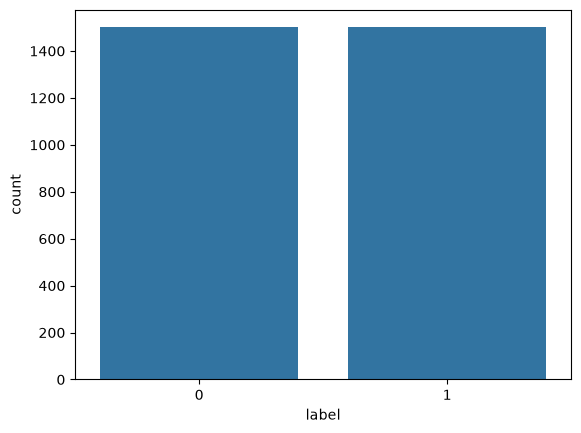

In [5]:
print("POSITIVE examples:")
print(df[df.label == 1]["text"].head(5).to_string(index=False))
print("\nNEGATIVE examples:")
print(df[df.label == 0]["text"].head(5).to_string(index=False))

sns.countplot(x="label", data=df); plt.show()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Tharushi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Positive: [('great', 201), ('good', 178), ('film', 105), ('phone', 88), ('movie', 86), ('one', 76), ('well', 68), ('best', 63), ('food', 60), ('place', 58), ('like', 56), ('love', 56), ('really', 56), ('service', 55), ('excellent', 52)]
Negative: [('bad', 100), ('movie', 96), ('phone', 80), ('one', 70), ('like', 69), ('food', 66), ('time', 62), ('would', 59), ('film', 58), ('place', 56), ('good', 53), ('service', 53), ('even', 48), ('back', 48), ('really', 47)]


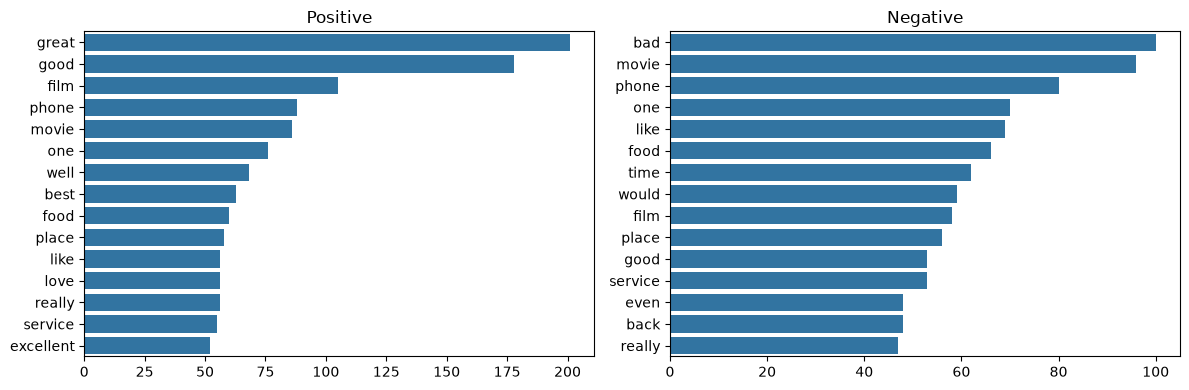

In [6]:
from collections import Counter
nltk.download("stopwords")
from nltk.corpus import stopwords
stop = set(stopwords.words("english"))

def top_words(series, n=15):
    words = " ".join(series).split()
    words = [w for w in words if w not in stop and len(w) > 2]
    return Counter(words).most_common(n)

pos_top = top_words(df[df.label == 1]["clean_text"])
neg_top = top_words(df[df.label == 0]["clean_text"])
print("Positive:", pos_top)
print("Negative:", neg_top)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, data, title in zip(ax, [pos_top, neg_top], ["Positive", "Negative"]):
    w, c = zip(*data)
    sns.barplot(x=list(c), y=list(w), ax=a); a.set_title(title)
plt.tight_layout(); plt.show()

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"],
    test_size=0.2, random_state=42, stratify=df["label"])
print(len(X_train), len(X_test))

2400 600


In [8]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(X_train)   # learn vocabulary from train only
X_test_bow = vectorizer.transform(X_test)
print(X_train_bow.shape)

(2400, 4479)


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

lr = LogisticRegression(max_iter=1000).fit(X_train_bow, y_train)
svm = LinearSVC().fit(X_train_bow, y_train)

--- Logistic Regression ---
Accuracy : 0.8216666666666667
Precision: 0.804416403785489
Recall   : 0.85
F1       : 0.826580226904376
              precision    recall  f1-score   support

           0       0.84      0.79      0.82       300
           1       0.80      0.85      0.83       300

    accuracy                           0.82       600
   macro avg       0.82      0.82      0.82       600
weighted avg       0.82      0.82      0.82       600

--- SVM ---
Accuracy : 0.81
Precision: 0.7835365853658537
Recall   : 0.8566666666666667
F1       : 0.8184713375796179
              precision    recall  f1-score   support

           0       0.84      0.76      0.80       300
           1       0.78      0.86      0.82       300

    accuracy                           0.81       600
   macro avg       0.81      0.81      0.81       600
weighted avg       0.81      0.81      0.81       600



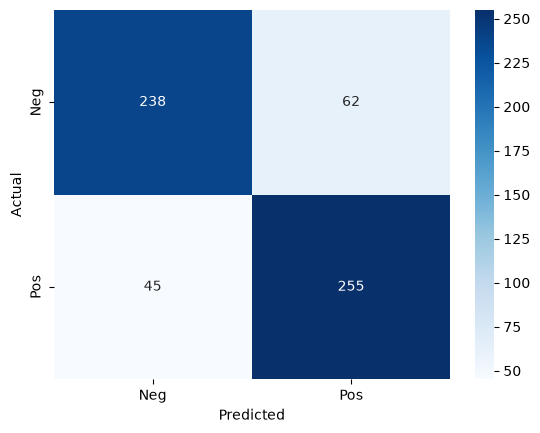

In [10]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

for name, model in [("Logistic Regression", lr), ("SVM", svm)]:
    pred = model.predict(X_test_bow)
    print(f"--- {name} ---")
    print("Accuracy :", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall   :", recall_score(y_test, pred))
    print("F1       :", f1_score(y_test, pred))
    print(classification_report(y_test, pred))

cm = confusion_matrix(y_test, lr.predict(X_test_bow))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [11]:
def predict_sentiment(sentence, model=lr):
    vec = vectorizer.transform([clean_text(sentence)])
    return "Positive" if model.predict(vec)[0] == 1 else "Negative"

for s in ["This phone is amazing, I love it!",
          "The food was terrible and the service was slow.",
          "It was okay I guess"]:
    print(s, "->", predict_sentiment(s))

This phone is amazing, I love it! -> Positive
The food was terrible and the service was slow. -> Negative
It was okay I guess -> Negative
